# AlexNet

![Структура AlexNet](alexnet.svg)

Исходная AlexNet рассчитана на изображения `224×224`, а изображения CIFAR-10 имеют размер `32×32`. Поэтому адаптируем архитектуру:

- **Вход:** `3×224×224` → `3×32×32`.
- **Первая свёртка:** 96 фильтров `11×11`, `stride=4` → 96 фильтров `3×3`, `stride=1`, `padding=1`.
- **Max pooling после 1-й, 2-й и 5-й свёрток:** окно `3×3`, `stride=2` → окно `3×3`, `stride=2`, `padding=1`. После трёх pooling размер карт будет `32 → 16 → 8 → 4`.
- **Вход первого полносвязного слоя:** `256×6×6 = 9216` признаков → `256×4×4 = 4096` признаков.
- **Первый полносвязный слой:** `9216 → 4096` → `4096 → 512`.
- **Второй полносвязный слой:** `4096 → 4096` → `512 → 256`.
- **Выходной слой:** `4096 → 1000` → `256 → 10`.

Во 2-й–5-й свёртках сохраняем число фильтров и размеры ядер. Также сохраняем `ReLU`, LRN после первых двух свёрток, `groups=2` во 2-й, 4-й и 5-й свёртках и `Dropout(0.5)` в двух скрытых полносвязных блоках. \
Упразднён слой `LRN` (Local Response Normalization), находившийся между слоями активации и пулинга в исходной AlexNet \
Упразднён параметр group=2 за ненадобностью распараллеливания обучения на 2 машины, как было в оригинале.

In [5]:
import torch.nn as nn
import torch
from typing import Callable
from torch.utils.data import TensorDataset
from data_utils import images_to_tensor, train_dataset_split, create_dataloader

## Работа с данными

In [6]:
X_train, y_train = images_to_tensor('data/trainLabels.csv', 'data/train', channels=3)

Создаём Dataset который умеет выдавать по одному значению, он используется в DataLoader

In [7]:
ds_train = TensorDataset(X_train, y_train)

Разобъём train на tain и val с помощью `train_dataset_split` из из data_utils

In [8]:
ds_train, ds_val = train_dataset_split(ds_train, train_size=0.8)

In [9]:
BATCH_SIZE = 128

Создаём DataLoader для train и val, которые будут выдавать наши пары (картинка, класс) батчами  при обучении

In [10]:
dl_train = create_dataloader(ds_train, BATCH_SIZE, shuffle=True)
dl_val = create_dataloader(ds_val, BATCH_SIZE, shuffle=False)

## Создание класса AlexNet

In [11]:
class AlexNet(nn.Module):
    """Упрощённая адаптация AlexNet для изображений CIFAR-10 размером 32x32."""

    def __init__(self, 
                 in_channels: int = 3, 
                 output_size: int = 10):
        
        super().__init__()

        modules = []
        conv_layers = [96, 256, 384, 384, 256]

        in_ = in_channels # количество входных каналов для свёртки
        for i in range(len(conv_layers)): # цикл добавления свёрточных блоков (смотреть схему)

            # свёртка
            if i == 1:
                modules.append(nn.Conv2d(
                    in_channels=in_,
                    out_channels=conv_layers[i],
                    kernel_size=5,
                    stride=1,
                    padding=2,
                    ))
            else:
                modules.append(nn.Conv2d(
                    in_channels=in_,
                    out_channels=conv_layers[i],
                    kernel_size=3,
                    stride=1,
                    padding=1,
                    ))
            in_ = conv_layers[i]

            modules.append(nn.ReLU()) # слой активации после какждой свёртки

            if i in [0, 1]:
                modules.append(nn.LocalResponseNorm(size=5)) # значение size=5 взято из оригинальной версии

            if i in [0, 1, 4]: # в блоках 1, 2, 5 есть maxpool
                modules.append(nn.MaxPool2d(kernel_size=3, stride=2, padding=1))

        # после всех свёрточных слоёв распрямляем значения в вектор, чтобы подать на вход линейному слою
        modules.append(nn.Flatten())
        # после выпрямления получаем вектор из 4096 чисел

        # 1 линейный слой на 512 нейронов
        modules.append(nn.Linear(4096, 512))
        modules.append(nn.ReLU())
        modules.append(nn.Dropout(0.5))

        # 2 линейный слой на 256 нейронов
        modules.append(nn.Linear(512, 256))
        modules.append(nn.ReLU())
        modules.append(nn.Dropout(0.5))

        # в конце добавляем выходной слой, дающий предсказания (логиты) для каждого из классов
        modules.append(nn.Linear(256, output_size))

        self.network = nn.Sequential(*modules)

    def forward(self, x):
        return self.network(x)

In [14]:
DEVICE = 'mps'

In [15]:
alexnet = AlexNet(3, 10).to(DEVICE)
loss_func = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(alexnet.parameters(), lr=1e-4)

In [16]:
from train_utils import train

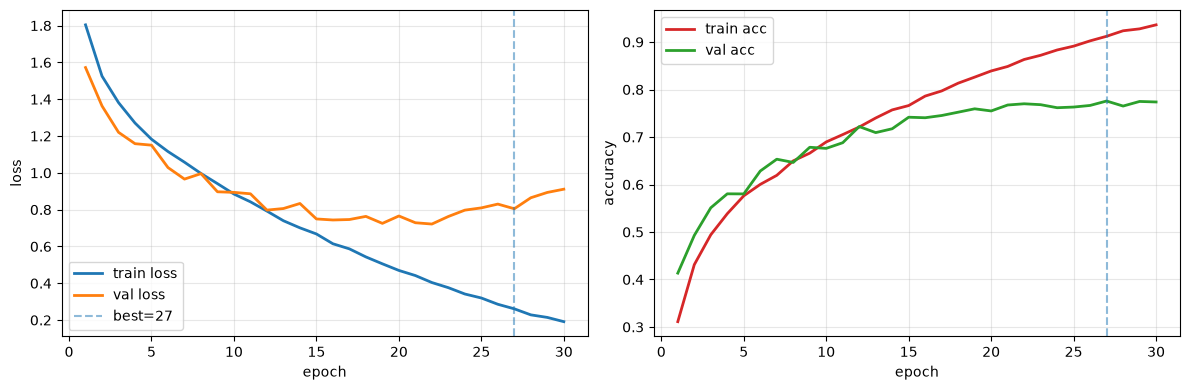

Best epoch = 27, best val_acc = 0.7758


,0
0,0.7758
1,27.0000


In [18]:
train(alexnet, optimizer, loss_func, dl_train, dl_val, "models/lenet5.pth", DEVICE, EPOCH_COUNT=30)